# 03 — Limpeza, estruturação e verificação automática da jurisprudência

Esta etapa trabalha com **19 arquivos ativos e 609.872 registros legíveis**, preservando a linhagem. Há uma base canônica em Parquet e uma derivada separada em CSV/Parquet com CPFs mascarados na seção **Proteção de dados pessoais**. O processamento ocorre em lotes. A cópia oficial adicional de 50.000 registros STF não integra o escopo ativo.

Os textos originais e a base canônica anterior permanecem separados e podem conter dados pessoais. A derivada protegida não exporta as colunas de texto original. Mascarar CPFs não constitui anonimização integral. Não há publicação automática, exclusão por duplicatas, treinamento ou indexação no RAG.

## Roteiro do notebook

Este notebook apresenta a preparação e a verificação da base.

1. Limpeza estrutural e normalização conservadora.
2. Proteção de dados pessoais e PLN leve.
3. [Fontes, versões, licenças e integridade](#fontes-proveniencia).
4. [Verificações automáticas, conteúdo, recorte e partições](#verificacao-automatica).
5. Reconciliação, gráficos, diagnóstico final e integração.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.display import Markdown
ROOT_JUR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
               if (p/'src/jurisprudencia/eda.py').is_file()),None)
if ROOT_JUR is None:raise FileNotFoundError('Raiz do projeto não encontrada.')
if str(ROOT_JUR) not in sys.path:sys.path.insert(0,str(ROOT_JUR))

from src.jurisprudencia import structure,audit,dataset
EXECUTAR_ESTRUTURACAO=False
if EXECUTAR_ESTRUTURACAO:
    STRUCT_REPORT,resumo_estrutura=structure.run(ROOT_JUR)
DATA_DIR,STRUCT_REPORT=dataset.locations(ROOT_JUR)
resumo_estrutura=json.loads((STRUCT_REPORT/'resumo_estruturacao.json').read_text(encoding='utf-8'))
manifestos_estrutura=json.loads((STRUCT_REPORT/'manifestos_arquivos.json').read_text(encoding='utf-8'))
print('Base canônica original (sem mascaramento):',DATA_DIR)
print('Relatórios:',STRUCT_REPORT)
# Escopo ativo da estruturação
resumo_estrutura=dict(resumo_estrutura)
resumo_estrutura['arquivos_em_quarentena_historico']=resumo_estrutura['arquivos_em_quarentena']
resumo_estrutura['arquivos_em_quarentena']=0
resumo_estrutura['arquivos_ativos']=len(manifestos_estrutura)
assert resumo_estrutura['arquivos_ativos']==19
assert all(m['arquivo']!='train-00002.parquet' for m in manifestos_estrutura)
assert sum(m['registros'] for m in manifestos_estrutura)==resumo_estrutura['registros']


Base canônica original (sem mascaramento): C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\1cfddb551ec7c1f00d5c9bf2b6b9ab7ba990b2a6202815bb092b94443b3cbc50
Relatórios: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\estruturacao\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\1cfddb551ec7c1f00d5c9bf2b6b9ab7ba990b2a6202815bb092b94443b3cbc50


In [2]:
from src.jurisprudencia import presentation
contexto_atual=presentation.context(ROOT_JUR)
display(Markdown(presentation.structure_status_markdown(contexto_atual)))


## Escopo e versões dos dados

O escopo ativo contém **19 arquivos e 609.872 registros**, em acordo com os notebooks 01 e 02. O arquivo ilegível foi excluído do escopo ativo; seu registro permanece somente no histórico. A origem de **18 dos 19 arquivos ativos** está confirmada por hash e tamanho; a origem individual do JSON TST continua pendente. A cópia oficial adicional de **50.000 registros STF permanece separada**.

**Base canônica original:** preserva os textos original e limpo, a linhagem e os sinais de revisão; pode conter dados pessoais. As tabelas de normalização e os sinais da auditoria referem-se a essa versão.

**Derivada protegida:** o CSV e os shards Parquet contêm texto/ementa com sequências compatíveis com CPF substituídas por `[CPF_REMOVIDO]`. Foram alterados **5.695 registros**, com **13.294 substituições**. A releitura integral validou os **609.872 registros** do CSV, sem resíduos dos padrões tratados nos campos de conteúdo. Os textos originais não foram exportados nessa derivada.

O mascaramento de CPF está concluído. A verificação automática posterior registra alertas de privacidade, inferência de conteúdo e sinais temáticos; outros dados pessoais não são considerados integralmente anonimizados. Os grupos e as partições foram recalculados após o PLN e conferidos para os vínculos conhecidos. Não houve publicação, indexação ou treinamento.

Referências: [Revisão](#verificacao-automatica), [Origens](#fontes-proveniencia) e [regras de proteção](../../docs/protecao_cpf_jurisprudencia.md).

**PLN leve concluído:** formatação/entidades HTML, NFC e separação de `ementa` e `inteiro_teor` foram auditados. O CSV final foi relido integralmente, e o mascaramento foi reaplicado aos textos decodificados. Candidatos a ruído e comparações antes/depois possuem verificações por regras; os trechos incertos permanecem preservados com alertas. Use `data/processed/jurisprudencia/pln_leve/ativa.json` para localizar a versão tratada.


## 1. Contrato de dados e mapeamento

Cada registro tem ID determinístico, arquivo/posição de origem, hash do arquivo, hash canônico do registro original, tribunal e método de identificação, processo original, CNJ sintático quando reconhecido, órgão julgador, relator, classe/tipo declarados, datas separadas, texto original/limpo e motivos de revisão. `linha_origem` é a linha física no JSONL e o índice do registro (base 1) no JSON em array ou Parquet.

O tribunal canônico só é preenchido com evidência estruturada reconhecida. Hipótese pelo nome do arquivo permanece hipótese. Assinatura **não é promovida a julgamento**; uma referência temporal alternativa guarda seu próprio tipo. Formatos antigos de processo permanecem preservados; a extração do CNJ não valida dígitos verificadores.

As colunas não mapeadas continuam recuperáveis no arquivo original por hash e posição. Não se afirma que strings contendo JSON tenham sido integralmente expandidas. Os identificadores de documento e seus namespaces precisam ser conferidos com o produtor.

In [3]:
display(pd.read_csv(STRUCT_REPORT/'schema_canonico.csv'))
display(pd.DataFrame([{k:m.get(k) for k in ('arquivo_id','arquivo','registros','texto_alterado','candidatos_tecnicos','saida_sha256')}
                      for m in manifestos_estrutura]))

,campo,tipo
0,registro_id,string
1,arquivo_id,string
2,arquivo_origem,string
3,arquivo_sha256,string
4,registro_original_sha256,string
5,documento_id_origem,string
6,tribunal,string
7,tribunal_original,string
8,tribunal_metodo,string
9,processo_original,string


,arquivo_id,arquivo,registros,texto_alterado,candidatos_tecnicos,saida_sha256
0,f01,jurisprudencia_trt13.jsonl,15730,0,15730,cc26bcec07144cc327654ef689453571ebee9993a22502...
1,f02,jurisprudencias_tst.json,10000,0,10000,94eb62919cf11e729fd38c12c716b7a9cd75b8150a10c2...
2,f03,train-00001.parquet,50000,40626,49848,1cb42c782c638f445db340820b6ceb5cae8d0ae1a4c8d9...
3,f04,train-00000.parquet,50000,49585,48463,688c52ae02d4f055c373d302aedc99823ea84d38cd6485...
4,f06,train-00005.parquet,50000,49371,50000,e64e92d665c879eb25d95939973c38bc1a7fdca0a7f141...
5,f07,part-00000.parquet,366,0,366,2bbfd9714cac4e016c68e7608c1aeb8766cb59b7e84257...
6,f08,part-00000 (1).parquet,18780,0,18780,a3c11f66925fa3cdf5bec2edd6a21604bf7dfabc358342...
7,f09,part-00000 (3).parquet,1114,0,1114,b58cb702ffc0078fd24745c3c8289ab194d7f67148e4bc...
8,f10,part-00000 (2).parquet,17714,0,17714,1e0ebd5b72ec4fb55c7b8dfe912b43748c6a4d038e6cf8...
9,f11,part-00000 (4).parquet,1,0,1,56dc3e9ed38d60a23f389d6e1c2026d05196526544f4b5...


## 2. Regras de limpeza e preservação

- Preservar `texto_original` e `ementa_original`, com versão limpa em colunas separadas.
- Extrair apresentação HTML quando reconhecida; ignorar script/style, separar células de tabelas e preservar o texto visível na ordem recebida. HTML não balanceado e RTF não extraído recebem sinais de revisão.
- Normalizar NFC Unicode, BOM inicial, quebras de linha, controles de apresentação e espaços, preservando parágrafos.
- **Não** remover negações, exceções, números, artigos, parágrafos, acentos ou stopwords; não corrigir mérito jurídico ou mojibake por suposição.
- Registrar operações e hashes. Quando o texto muda, os offsets originais não são automaticamente reutilizáveis. Não foi criado um mapa de alinhamento bruto → limpo; o chunking futuro deve trabalhar com sua versão textual identificada.

“Candidato técnico de indexação” significa somente texto/tribunal reconhecidos e ausência de certos impedimentos de formato. Não significa aprovação jurídica, de privacidade, de licença ou de pertinência trabalhista.

In [4]:
display(pd.Series({k:v for k,v in resumo_estrutura.items() if not isinstance(v,(dict,list))},name='resultado').to_frame())
display(pd.Series(resumo_estrutura['operacoes'],name='registros_com_operacao').to_frame())
display(pd.read_csv(STRUCT_REPORT/'motivos_revisao.csv'))

,resultado
protocolo,jurisprudencia-estrutura-v1
inventario_sha256,71714343f9fd896da188fc14ed120ae9b8343b744455f4...
codigo_estrutura_sha256,295f90387d3c958de74e7aeda23d114a13ed7a10c79a63...
codigo_funcoes_auditoria_sha256,772354ed79c2da034628522bf7705bf82f6b9414f2fa91...
executado_em_utc,2026-11-14T01:19:23.033191+00:00
pasta_dados,data\processed\jurisprudencia\71714343f9fd896d...
arquivos_estruturados,19
arquivos_em_quarentena,0
registros,609872
texto_alterado,186311


,registros_com_operacao
espacos_e_linhas_vazias_normalizados,174352
quebras_de_linha_normalizadas,16178
unicode_nfc,804
html_para_texto_visivel,8
controles_de_apresentacao_removidos,46343


,motivo,registros_com_sinal
0,campos_de_partes_ou_contato_na_origem,144824
1,cpf_candidato_checksum_valido,3281
2,email_candidato,776
3,possivel_mojibake_nao_corrigido,13
4,publicacao_anterior_julgamento,106
5,sem_processo_na_origem,1371
6,tribunal_sem_identificacao_estruturada,1689
7,unicode_substituicao_revisar,56


## 3. Proteção de dados pessoais

Nesta etapa da limpeza, uma **derivada separada** substitui sequências compatíveis com CPF por `[CPF_REMOVIDO]`, antes de qualquer chunking, embedding ou envio ao modelo. São tratados CPF formatado, sem pontuação e com separadores reconhecidos, inclusive DV inválido. Outros números de 11 dígitos também podem ser mascarados de forma conservadora. O processo CNJ contínuo de 20 dígitos é preservado.

A base canônica apresentada nas tabelas anteriores permanece preservada e contém texto original/limpo. Ela **não é a exportação protegida**. O CSV e os novos shards Parquet usam somente `texto_protegido`, `ementa_protegida` e metadados selecionados, também mascarados. Não incluem `texto_original`, `texto_limpo`, `ementa_original`, partes, JSONs brutos ou URLs da origem. Há um ID de linhagem para localizar o original no armazenamento separado; não há mapa de CPF para reidentificação.

O CSV é UTF-8, com cabeçalho, campos entre aspas conforme necessário e quebras de linha preservadas dentro do texto. Sua validação relê todas as linhas, confere a quantidade de registros e procura resíduos do padrão nos textos e metadados de conteúdo. Os IDs técnicos são verificados separadamente pelo formato estrito (hash hexadecimal/código de arquivo), preservando a linhagem; sequências numéricas dentro de hashes não são tratadas como CPFs. As estatísticas não exibem CPFs reais. CSV pode ser grande; Parquet permite leitura em lotes. A derivada continua ignorada pelo Git.

**Limite:** este é mascaramento de CPFs, não anonimização completa. Nomes, endereços, e-mails e outras informações não são integralmente tratados por esta regra; formas por extenso ou ofuscações não reconhecidas podem escapar. A exportação não representa liberação automática de publicação ou indexação. Uma futura entrada do RAG deve partir da versão protegida, após as revisões restantes. O chunking deve recalcular offsets sobre `texto_protegido`, sem reutilizar offsets da versão anterior.

Para executar novamente a transformação completa: `.venv/Scripts/python.exe scripts/proteger_cpf_jurisprudencia.py`. A célula abaixo lê os resultados já processados; o parâmetro pesado fica desligado por padrão.


In [5]:
from src.jurisprudencia import privacy
EXECUTAR_PROTECAO_CPF=False
if EXECUTAR_PROTECAO_CPF:
    PROTECTION_REPORT,resumo_protecao=privacy.run(ROOT_JUR)
else:
    PROTECTION_REPORT,resumo_protecao=privacy.load(ROOT_JUR)
assert resumo_protecao['registros']==resumo_estrutura['registros']
assert resumo_protecao['validacao']['registros_csv_relidos']==resumo_estrutura['registros']
assert resumo_protecao['validacao']['sequencias_compativeis_residuais']==0
assert not (set(resumo_protecao['colunas']) & privacy.FORBIDDEN)
print('Conferindo o hash do CSV protegido completo (aproximadamente 13 GB)...')
assert audit.hash_file(ROOT_JUR/resumo_protecao['csv'])==resumo_protecao['csv_sha256']
print('Integridade do CSV protegido confirmada.')
display(pd.Series({k:resumo_protecao[k] for k in ('registros','registros_com_mascaramento','sequencias_compativeis_mascaradas','csv_bytes','originais_preservados','anonimizado_integralmente')},name='protecao_cpf').to_frame())
display(pd.Series(resumo_protecao['mascaramentos_por_campo'],name='substituicoes_por_campo').to_frame())
display(pd.Series(resumo_protecao['validacao'],name='validacao_csv').to_frame())
print('CSV protegido:',ROOT_JUR/resumo_protecao['csv'])
print('Relatório:',PROTECTION_REPORT)
print('Colunas exportadas:',resumo_protecao['colunas'])
print(resumo_protecao['limites'])


Conferindo o hash do CSV protegido completo (aproximadamente 13 GB)...
Integridade do CSV protegido confirmada.
CSV protegido: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\protecao_cpf\304920c0adcd24fb01b29d65811962e8797768aca6899fe7828a931a163f3a48\jurisprudencia_cpf_protegido.csv
Relatório: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\protecao_cpf\304920c0adcd24fb01b29d65811962e8797768aca6899fe7828a931a163f3a48
Colunas exportadas: ['registro_id', 'arquivo_id', 'tribunal', 'processo_cnj', 'orgao_julgador', 'relator', 'classe_origem', 'tipo_decisao_origem', 'data_julgamento', 'data_publicacao', 'data_assinatura', 'texto_protegido', 'ementa_protegida', 'cpf_mascarado', 'privacidade_status']
Mascaramento de sequências compatíveis com CPF, inclusive DV inválido. Pode mascarar outros números de 11 dígitos. Não cobre formas por extenso, todas as ofuscações, nomes, endereços ou outros dados pessoais. Não libera publicação ou indexação.


,protecao_cpf
registros,609872
registros_com_mascaramento,5695
sequencias_compativeis_mascaradas,13294
csv_bytes,12951131339
originais_preservados,True
anonimizado_integralmente,False


,substituicoes_por_campo
registro_id,0
arquivo_id,0
tribunal,0
processo_cnj,0
orgao_julgador,0
relator,0
classe_origem,0
tipo_decisao_origem,0
data_julgamento,0
data_publicacao,0


,validacao_csv
registros_csv_relidos,609872
sequencias_compativeis_residuais,0
colunas_originais_expostas,False
metodo,Releitura integral do CSV UTF-8 com campos mul...


## 4. Limpeza leve e normalização conservadora, preservando o texto jurídico (PLN)

### Critérios da limpeza leve e normalização conservadora (PLN)

| Etapa | Procedimento e preservação |
| --- | --- |
| **Limpar a formatação** | Remover HTML reconhecido e converter entidades, inclusive `&nbsp;` sem tags. Corrigir espaços repetidos, mantendo limites de parágrafos, listas e títulos; conservar a numeração das listas ordenadas reconhecidas. |
| **Normalizar caracteres** | Aplicar Unicode **NFC** e uniformizar quebras de linha. Preservar acentos, pontuação, números e referências como `art. 482`, `§ 2º` e `Súmula 331`. |
| **Tratar ruído de extração** | Identificar linhas recorrentes de início/fim como candidatas a cabeçalho/rodapé, sem removê-las automaticamente. Sinalizar palavras partidas. Unir partes somente com origem PDF confirmada e palavra aprovada; preservar hífens legítimos, como em `pré-judicial`. Neste lote, a origem PDF não está confirmada, portanto não há junção automática. |
| **Auditar o resultado** | Contar vazios, ausências e duplicatas exatas. Comparar amostras antes/depois por invariantes e marcadores jurídicos. Preservar `ementa` e `inteiro_teor` separados; texto de busca e variantes também ficam identificados. |

**Evitar remover stopwords, acentos ou pontuação.** “Não” e “salvo” podem mudar o sentido da decisão. Esta etapa não faz lematização, stemming, classificação temática ou reescrita jurídica.

O processamento parte da derivada com CPFs mascarados. A decodificação HTML pode revelar números antes codificados, por isso o mascaramento é reaplicado aos textos normalizados. O original e a derivada anterior permanecem separados. As amostras reais são salvas somente em dados processados ignorados pelo Git: podem conter nomes ou outros dados pessoais, e não são exibidas nos relatórios do notebook.

Os candidatos a cabeçalho/rodapé são repetições exatas nas duas primeiras/últimas linhas, entre 8 e 200 caracteres, presentes em pelo menos 10 documentos. Isso é triagem, não prova de ruído. As regras preservam esses trechos e registram alertas computacionais, sem exclusão automática de repetições.


A transformação integral foi executada por `scripts/preprocessar_pln_leve_jurisprudencia.py`. A célula lê os resultados salvos, sem reprocessar o corpus.

In [6]:
from src.jurisprudencia import light_nlp
PLN_REPORT,resumo_pln=light_nlp.load(ROOT_JUR)
assert resumo_pln['registros']==contexto_atual['structured']['registros']
assert resumo_pln['base_cpf_csv_sha256']==contexto_atual['cpf_protection']['csv_sha256']
assert resumo_pln['validacao_csv']['registros_csv_relidos']==resumo_pln['registros']
assert resumo_pln['validacao_csv']['residuos_padrao_cpf']==0
assert 'ementa' in resumo_pln['colunas'] and 'inteiro_teor' in resumo_pln['colunas']
assert (ROOT_JUR/resumo_pln['csv']).exists()
from src.jurisprudencia.pln_dataset import open_dataset as open_pln_dataset
assert open_pln_dataset(ROOT_JUR).count_rows()==resumo_pln['registros']
display(pd.Series(resumo_pln['indicadores'],name='auditoria_pln_leve').to_frame())
display(pd.Series(resumo_pln['operacoes'],name='campos_com_operacao').to_frame())
display(pd.read_csv(PLN_REPORT/'duplicatas_exatas.csv'))
bordas_pln=pd.read_csv(PLN_REPORT/'cabecalhos_rodapes_candidatos.csv')
display(bordas_pln.head(20))
print('Candidatos recorrentes por fingerprint, sem texto ou nomes; não removidos:',len(bordas_pln))
print('Amostras comparadas automaticamente:',resumo_pln['amostras'],'| reduções dos marcadores monitorados:',resumo_pln['indicadores']['amostras_com_marcadores_juridicos_reduzidos_revisar'])
print('Amostra antes/depois (não exibida):',ROOT_JUR/resumo_pln['amostra_local'])
print('CSV após PLN:',ROOT_JUR/resumo_pln['csv'])
print('Leitura somente dos shards: open_pln_dataset(ROOT_JUR); amostra antes/depois excluída do corpus.')
print('Relatório:',PLN_REPORT)
print(resumo_pln['politica_pdf'])
print('Limites: PLN de formato e regras documentadas; não comprova mérito jurídico, integralidade de documentos ou anonimização completa.')
# Exemplos sintéticos: sem nomes, números de processo ou CPFs reais.
exemplos_pln=['Na\u0303o&nbsp;  aplicar art. 482; § 2º. Salvo Súmula 331.',
              '<h2>Título</h2><p>Não retirar.</p><ul><li>Salvo exceção.</li></ul>',
              'pré-judicial\ntra-\nbalhista']
display(Markdown('**Exemplos sintéticos antes/depois** — a amostra real permanece no arquivo local para revisão.'))
display(pd.DataFrame([{'antes':t,'depois':light_nlp.clean_light(t)[0]} for t in exemplos_pln]))


Candidatos recorrentes por fingerprint, sem texto ou nomes; não removidos: 1537
Amostras comparadas automaticamente: 55 | reduções dos marcadores monitorados: 0
Amostra antes/depois (não exibida): C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee\amostra_antes_depois.parquet
CSV após PLN: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee\jurisprudencia_pln_leve.csv
Leitura somente dos shards: open_pln_dataset(ROOT_JUR); amostra antes/depois excluída do corpus.
Relatório: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\pln_leve\349ae9df1d20a5b88cee56f116eba2d8e2a3e104e013c7a7b8cf084d132ac1ee
Origem PDF não confirmada: nenhuma junção automática; correção exige PDF confirmado e vocabulário aprovado.
Limites: PLN de formato e regras documentadas; não comprova mérito jurídi

,auditoria_pln_leve
campos_com_hifen_em_fim_de_linha_revisar,355065
campos_com_entidades_residuais_revisar,3
campos_com_substituicao_unicode_revisar,56
campos_ausentes_inteiro_teor,15730
campos_ausentes_texto_busca,609872
campos_ausentes_texto_outro,609872
campos_ausentes_ementa_alternativa,609872
registros,609872
textos_principais_vazios_antes,0
textos_principais_vazios_depois,0


,campos_com_operacao
espacos_normalizados_paragrafos_preservados,5
entidades_html_convertidas,10


,campo,grupos_exatos_repetidos,ocorrencias_excedentes
0,texto_principal,1602,13607
1,ementa,2560,8833
2,inteiro_teor,966,11483
3,texto_busca,0,0


,posicao,linha_sha256,documentos,status
0,inicio,5eb541bb1f805aeaf120f4debf86e28ed9af106d7acf66...,331831,candidato_repetido_nao_removido
1,fim,fd8ce230fd364ccc541a7b8d908952261bf48fc9524a22...,244413,candidato_repetido_nao_removido
2,fim,d183687f6af2912b8036db4c295e5bbbc55b535d565b57...,89941,candidato_repetido_nao_removido
3,inicio,71886400dfc1df47e5baf8dd0e62207c6a69f03401e277...,68653,candidato_repetido_nao_removido
4,fim,cca232cc3888c2e24079b9524994fd7dead4bfce8be156...,61762,candidato_repetido_nao_removido
5,inicio,ecc6ea357e2f10534ff12ad7a9ca771e81050b4606c484...,32574,candidato_repetido_nao_removido
6,inicio,dd058b2e3d6f158ee7f840262290610b6f0c321bb203e3...,30343,candidato_repetido_nao_removido
7,fim,5b8d7d259935611e40f522bd559fdf3e887d432a9f8cd6...,25557,candidato_repetido_nao_removido
8,fim,d5da50549bf94660397a4d7a5e3cd144f0e05b8598c877...,15428,candidato_repetido_nao_removido
9,inicio,4d7b068daef57c011837843d29296890e1e18b07a23c5d...,11089,candidato_repetido_nao_removido


**Exemplos sintéticos antes/depois** — a amostra real permanece no arquivo local para revisão.

,antes,depois
0,Não&nbsp; aplicar art. 482; § 2º. Salvo Súmu...,Não aplicar art. 482; § 2º. Salvo Súmula 331.
1,<h2>Título</h2><p>Não retirar.</p><ul><li>Salv...,Título\n\nNão retirar.\n\n• Salvo exceção.
2,pré-judicial\ntra-\nbalhista,pré-judicial\ntra-\nbalhista


<a id="fontes-proveniencia"></a>


## 5. Fontes, proveniência e integridade dos arquivos

Atualização após a pessoa usuária informar seis referências de origem. As evidências oficiais acessíveis foram salvas em revisão fixa. A atribuição de cada arquivo é feita por SHA-256 e tamanho, não apenas por nome. Esta atualização sucede o retrato de pendências do seção de verificação automática.

In [7]:
from pathlib import Path
import json,sys
import pandas as pd
from IPython.display import display
ROOT_JUR=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'src/jurisprudencia/audit.py').is_file())
if str(ROOT_JUR) not in sys.path:sys.path.insert(0,str(ROOT_JUR))
from src.jurisprudencia import audit
SOURCE_DIR=ROOT_JUR/'reports/jurisprudencia/origens_huggingface'
summary=json.loads((SOURCE_DIR/'rastreabilidade_atual_resumo.json').read_text(encoding='utf-8'))
recovery=json.loads((SOURCE_DIR/'recuperacao_shard.json').read_text(encoding='utf-8'))
display(pd.Series(summary,name='resultado').to_frame())

,resultado
verificado_em_utc,2026-11-14T01:57:52.807589+00:00
arquivos_recebidos,20
arquivos_locais_com_hash_confirmado,18
arquivos_locais_sem_correspondencia,2
arquivos_por_dataset,"{'zeraulalmeida/Jurisprudencia_TRT_13': 1, 'ce..."
arquivos_train_recebidos,"[train-00001.parquet, train-00000.parquet, tra..."
inventario_remoto_celsowm_shards,16
datasets,[{'dataset': 'celsowm/jurisprudencias_br_full'...
observacao,Os 16 shards são o inventário remoto; somente ...
base_canonica_alterada,False


### 5.1. Evidências de origem e licença

Os dois repositórios de celsowm e o RepoJus declaram `cc-by-4.0`. No RepoJus, o README delimita a licença à seleção, organização, normalização, metadados e documentação. O dataset TRT-13 declara MIT. Essas são declarações dos publicadores e não pareceres jurídicos sobre dados pessoais ou direitos de terceiros. As revisões consultadas não provam a data ou revisão do download original.

O arquivo `rastreabilidade_atual.json` guarda todos os locais remotos coincidentes. Os mesmos bytes de três arquivos estão publicados em dois repositórios; por isso as contagens por dataset se sobrepõem.

Fontes: [jurisprudencias_br_full](https://huggingface.co/datasets/celsowm/jurisprudencias_br_full), [jurisprudencias_br](https://huggingface.co/datasets/celsowm/jurisprudencias_br).

In [8]:
display(pd.DataFrame(summary['datasets']))
display(pd.read_csv(SOURCE_DIR/'rastreabilidade_atual.csv'))
assert summary['arquivos_locais_com_hash_confirmado']==18
assert summary['arquivos_locais_sem_correspondencia']==2
print('São 16 shards no inventário remoto, mas apenas quatro train-* no lote local original:',summary['arquivos_train_recebidos'])

São 16 shards no inventário remoto, mas apenas quatro train-* no lote local original: ['train-00001.parquet', 'train-00000.parquet', 'train-00002.parquet', 'train-00005.parquet']


,dataset,commit_consultado,licenca_declarada,gated,snapshot,schema_version,gerado_em,status,versao_informada_pessoa_usuaria
0,celsowm/jurisprudencias_br_full,fc61bf96c3516b8d749d3376a84641e4eb7e34b5,cc-by-4.0,False,NaN,NaN,NaN,NaN,NaN
1,celsowm/jurisprudencias_br,8df8ce3e629f490a0c82edca1dbe98ca73c5ecc3,cc-by-4.0,False,NaN,NaN,NaN,NaN,NaN
2,CEIA-COREJUR/processos,NaN,NaN,NaN,NaN,NaN,NaN,API_HTTP_401,2.1.0
3,costadev00/stf-acordaos,43dd394cdf2a03696d7978de5013398fd18aa572,cc-by-4.0,manual,NaN,NaN,NaN,NaN,NaN
4,efaraneda/repojus,91aa953b3c976a8688135dea49cf6644f7732243,cc-by-4.0,False,v3,3.0.0,2026-10-30T19:30:48Z,NaN,NaN
5,zeraulalmeida/Jurisprudencia_TRT_13,c75af60e9435d8d6b183f936c68a1d4d797d81b9,mit,False,NaN,NaN,NaN,NaN,NaN


,arquivo_id,arquivo_local,sha256_local,bytes_local,status,dataset,caminho_original,commit_consultado,licenca_declarada,escopo_licenca,evidencia,registros_remotos
0,f01,jurisprudencia_trt13.jsonl,88efe90ce20b880b75c04a9a0f3b80c2a7892139d6a310...,41527321,confirmado_sha256_tamanho,zeraulalmeida/Jurisprudencia_TRT_13,data/jurisprudencia_trt13.jsonl,c75af60e9435d8d6b183f936c68a1d4d797d81b9,mit,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
1,f02,jurisprudencias_tst.json,4eb6de499a97519c8d5cbd6df1268d621fa9a279b75541...,123669364,sem_correspondencia_nas_revisoes_consultadas,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,f03,train-00001.parquet,ff0d36929229a52412fdc1e4103c47b42ab8264b2f0099...,225364323,confirmado_sha256_tamanho,celsowm/jurisprudencias_br_full,train-00001.parquet,fc61bf96c3516b8d749d3376a84641e4eb7e34b5,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
3,f03,train-00001.parquet,ff0d36929229a52412fdc1e4103c47b42ab8264b2f0099...,225364323,confirmado_sha256_tamanho,celsowm/jurisprudencias_br,full/train-00001.parquet,8df8ce3e629f490a0c82edca1dbe98ca73c5ecc3,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
4,f04,train-00000.parquet,c6a05e79ebc8f7134d2e0bb7156991ecaabdc89c4b25df...,432647327,confirmado_sha256_tamanho,celsowm/jurisprudencias_br_full,train-00000.parquet,fc61bf96c3516b8d749d3376a84641e4eb7e34b5,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
5,f04,train-00000.parquet,c6a05e79ebc8f7134d2e0bb7156991ecaabdc89c4b25df...,432647327,confirmado_sha256_tamanho,celsowm/jurisprudencias_br,full/train-00000.parquet,8df8ce3e629f490a0c82edca1dbe98ca73c5ecc3,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
6,f05,train-00002.parquet,7359c128ce3c3e0f81ecd9f822469a53b27f14c7e42ecc...,222818285,sem_correspondencia_nas_revisoes_consultadas,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,f06,train-00005.parquet,0cbf1b748a88318e20d76b76abe0a4437c54b7b18b7752...,296881832,confirmado_sha256_tamanho,celsowm/jurisprudencias_br_full,train-00005.parquet,fc61bf96c3516b8d749d3376a84641e4eb7e34b5,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
8,f06,train-00005.parquet,0cbf1b748a88318e20d76b76abe0a4437c54b7b18b7752...,296881832,confirmado_sha256_tamanho,celsowm/jurisprudencias_br,full/train-00005.parquet,8df8ce3e629f490a0c82edca1dbe98ca73c5ecc3,cc-by-4.0,Licença declarada pelo publicador; não substit...,API oficial LFS,NaN
9,f07,part-00000.parquet,bc25c4a23b4ea11a8d22d3e67b01785b555e2f2e3e7184...,1752046,confirmado_sha256_tamanho,efaraneda/repojus,data/v3/p_tribunal=TRT17/p_ano=2019/part-00000...,91aa953b3c976a8688135dea49cf6644f7732243,cc-by-4.0,"Seleção, organização, normalização, metadados ...",snapshot-manifest.json,366.0


### 5.2. Cópia oficial do shard e diferenças em relação ao arquivo local

O shard `train-00002.parquet` oficial foi baixado em revisão fixa, teve SHA-256 comparado ao manifesto LFS e foi integralmente lido com PyArrow. Contém 50.000 registros declarados como STF. Não se confunde leitura técnica com autenticidade jurídica ou pertinência trabalhista.

O arquivo local em quarentena tem 222.818.285 bytes; o oficial tem 122.977.661 bytes. Os hashes e os trechos inicial/final de 64 KiB diferem. Portanto, não há evidência suficiente para declarar que os registros do arquivo local foram recuperados. O original foi preservado e a cópia oficial fica separada, fora da base canônica e das métricas anteriores.

In [9]:
import pyarrow.parquet as pq
candidate=ROOT_JUR/recovery['arquivo_local']
assert audit.hash_file(candidate)==recovery['sha256']
assert candidate.stat().st_size==recovery['bytes']
assert pq.ParquetFile(candidate).metadata.num_rows==recovery['registros_lidos_integralmente']
assert not recovery['incorporado_base_canonica']
display(pd.Series(recovery,name='copia_oficial').to_frame())

,copia_oficial
dataset,celsowm/jurisprudencias_br_full
commit,fc61bf96c3516b8d749d3376a84641e4eb7e34b5
arquivo_remoto,train-00002.parquet
arquivo_local,data\raw\jurisprudencia\recuperacao\train-0000...
sha256,d0f5fc249168921cab5ba7e01d0425d0b9f32376937c33...
bytes,122977661
registros_lidos_integralmente,50000
tribunais,{'stf': 50000}
original_alterado,False
prefixo_64k_igual,False


### 5.3. Consulta automática de URLs oficiais

A amostra consulta somente URLs públicas HTTPS em domínios judiciais, com redirecionamentos restritos. O relatório distingue HTTP 200, bloqueios/respostas e erros. Não expõe o caminho completo ou parâmetros das URLs e não declara equivalência documental pelo status HTTP.

In [10]:
from src.jurisprudencia import automatic_review
AUTO_DIR,resumo_auto=automatic_review.load(ROOT_JUR)
consulta_fontes=json.loads((AUTO_DIR/'fontes_oficiais_verificadas.json').read_text(encoding='utf-8'))
display(pd.DataFrame(consulta_fontes['resultados']))
print(consulta_fontes['limite'])


Disponibilidade HTTP não comprova identidade do texto, atualidade jurídica ou autenticidade de cada decisão. Comparação documental com fonte oficial não implementada neste módulo.


,registro_id,host,url_sha256,conteudo_documental_comparado,status,http_status
0,00000ceb69ab15138f6faedaf6ce0640ed7b973993b83a...,jurisprudencia.tst.jus.br,339023e9b43bf2fb1e99a987662ed35f784919b192674b...,False,acessivel_http,200
1,000018fae3413a1b6c9a1ce8127a698632295b265fb9e6...,jurisprudencia.jt.jus.br,027f2367624918cda8e37878e73aead89bf1dd587bd5ef...,False,resposta_http,403
2,00003c6a409bf83e4e179e8690920862dfa97a5044f129...,jurisprudencia.tst.jus.br,c307e4ef9a84e5f1635d76fc2fed5557e8f11b03492f94...,False,acessivel_http,200
3,00014b8ad78dbc6f3e46eeb36b918634a2103373a4460b...,pje.trt13.jus.br,dc8dc5a86fe698ef437b2add97b6bd588ff153bb7061c2...,False,resposta_http,403
4,00022e4e44b5ab02cc4f3576db5e7489e163b64075d80e...,pje.trt13.jus.br,dc8dc5a86fe698ef437b2add97b6bd588ff153bb7061c2...,False,resposta_http,403
5,000399f24f21033e3fc69c33f4f5d9dc922c442430ab41...,pje.trt10.jus.br,0332964105fac19e49670f61518e0cb56ab71b5aeda2e4...,False,resposta_http,405
6,0003aec611f86e7ebd38d4b2b0abc902b46ad270b61709...,jurisprudencia.jt.jus.br,56f3bd97bb4a949e2511e5e8da8df9f12277485df0b107...,False,resposta_http,403
7,0005022c16b69ea03978d92de8273dc39767fa7234f039...,pje.trt10.jus.br,a1c10b0e0d7af13fccf1ca0ffe2229011aacaa7e9f0aa1...,False,resposta_http,405


### 5.4. Proveniência e verificações automatizadas

Estão confirmadas por hash e tamanho as origens de 18 dos 20 arquivos recebidos, equivalentes a 18 dos 19 arquivos ativos. O arquivo ilegível permanece apenas no histórico. O JSON TST ativo não teve correspondência exata e recebe alerta de proveniência; isso não é preenchido por suposição.

O seção de verificação automática contém critérios de recorte, inferência de conteúdo, amostras computacionais e partições pós-PLN. A consulta de URLs oficiais abaixo mede disponibilidade HTTP; não compara o texto integral remoto com o local. A comparação documental integral é uma integração adicional não implementada.

A cópia oficial adicional de 50.000 registros STF permanece separada. O escopo ativo continua em 609.872 registros. Nenhum registro foi publicado externamente ou indexado automaticamente.


<a id="verificacao-automatica"></a>


## 6. Verificação automática e prontidão da base

Consolida critérios de uso/recorte, inferência de conteúdo, amostras automáticas, proveniência, relações entre registros e partições pós-PLN. Todos os resultados são baseados em rotinas executadas e evidências salvas. O fluxo é computacional e registra o alcance dos métodos aplicados.

In [11]:
from pathlib import Path
import sys,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT_JUR=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'src/jurisprudencia/automatic_review.py').is_file())
if str(ROOT_JUR) not in sys.path:sys.path.insert(0,str(ROOT_JUR))
from src.jurisprudencia import automatic_review,audit
REVIEW_DIR,resumo_auto=automatic_review.load(ROOT_JUR)
assert audit.hash_file(ROOT_JUR/resumo_auto['indice'])==resumo_auto['indice_sha256']
assert resumo_auto['registros']==609872
print('Relatórios automáticos:',REVIEW_DIR)

Relatórios automáticos: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\automacao\4dfbcfe6b1cf461dbea9698d1b6f8b5843ef985702621493467483ce57b49bce


### 6.1. Uso, recorte e separação dos objetivos

Critérios versionados para RAG trabalhista, proposta de avaliação por grupos e ajuste fino desabilitado. Não se presume que dados adequados para recuperação sejam automaticamente gabaritos de avaliação ou exemplos supervisionados.

In [12]:
criterios=json.loads((REVIEW_DIR/'criterios_uso_recorte.json').read_text(encoding='utf-8'))
criterios['automacao']['limite']='Sinais não comprovam integralidade do documento, pertinência jurídica ou anonimização completa. Integrações adicionais têm seu estado técnico documentado.'
display(pd.Series(criterios,name='politica_automatica').to_frame())
display(pd.read_csv(REVIEW_DIR/'recorte_tribunais.csv'))

,politica_automatica
versao,lexia-preparacao-automatica-v1
uso_principal,RAG de jurisprudência trabalhista
rag,"{'tribunais_prioritarios': ['TST', 'TRT-*'], '..."
avaliacao,{'particoes': 'Proposta 80/10/10 por component...
ajuste_fino,"{'habilitado': False, 'motivo': 'Objetivo não ..."
automacao,"{'validacao': 'Regras, invariantes e evidência..."


,tribunal,triagem,candidato,registros
0,STF,sem_sinal_suficiente_no_prefixo,False,141350
1,STF,sinal_lexical_trabalhista,False,15
2,STF,sinal_lexical_trabalhista,True,6946
3,TRT-10,jurisdicao_trabalhista,True,30486
4,TRT-13,jurisdicao_trabalhista,False,1
5,TRT-13,jurisdicao_trabalhista,True,15729
6,TRT-17,jurisdicao_trabalhista,True,37975
7,TST,jurisdicao_trabalhista,False,10033
8,TST,jurisdicao_trabalhista,True,365648
9,não identificado,sem_sinal_suficiente_no_prefixo,False,1689


### 6.2. Conteúdo declarado e inferido, estrutura e cobertura

O tipo declarado é confrontado com tamanho e marcadores estruturais no prefixo de até 8.000 caracteres. Texto com menos de 500 caracteres rotulado como inteiro teor é sinalizado; isso não prova que seja ementa. Sinais temáticos são lexicais e não classificação semântica exaustiva.

A estrutura interna dos JSONs serializados foi amostrada automaticamente em até 32 registros por campo/arquivo. A cobertura é amostral e os valores internos não são exibidos.

In [13]:
display(pd.read_csv(REVIEW_DIR/'cobertura_conteudo.csv'))
display(pd.read_csv(REVIEW_DIR/'estrutura_json_serializado_amostra.csv'))
display(pd.read_csv(REVIEW_DIR/'tamanho_textos.csv'))

,tribunal,tipo_declarado,tipo_inferido,registros
0,STF,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,107464
1,STF,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,36551
2,STF,inteiro_teor_declarado,texto_curto_rotulado_inteiro_teor,4296
3,TRT-10,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,30422
4,TRT-10,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,64
5,TRT-13,ementa,ementa_declarada,15730
6,TRT-17,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,37975
7,TST,inteiro_teor_declarado,inteiro_teor_com_indicio_estrutural,363894
8,TST,inteiro_teor_declarado,inteiro_teor_declarado_sem_indicio_no_prefixo,1754
9,TST,inteiro_teor_declarado,texto_curto_rotulado_inteiro_teor,10033


,arquivo_id,campo,registros_amostrados,json_validos,json_invalidos,vazios,objetos,listas,cobertura,valores_expostos
0,f03,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
1,f04,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
2,f06,data_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
3,f07,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
4,f08,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
5,f09,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
6,f10,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
7,f11,metadata_extra_json,1,1,0,0,1,0,primeiros_32_registros_por_campo_e_arquivo,False
8,f12,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False
9,f13,metadata_extra_json,32,32,0,0,32,0,primeiros_32_registros_por_campo_e_arquivo,False


,faixa,registros
0,500-1999,34923
1,2000-9999,190067
2,80-499,6501
3,>=10000,368340
4,<80,10041


### 6.3. Diagnóstico automático e amostras

As regras detectam textos curtos, datas ausentes/futuras, cronologia suspeita, rótulos de conteúdo e ausência de correspondência de origem. Amostras de textos curtos, longos e com alertas são selecionadas por IDs estáveis, por arquivo, sem exibir os textos. A comparação antes/depois do PLN mede os marcadores jurídicos monitorados; outros aspectos semânticos não são comprovados por esses testes.

In [14]:
display(pd.read_csv(REVIEW_DIR/'alertas_automaticos.csv'))
amostras_auto=pd.read_csv(REVIEW_DIR/'amostras_automaticas.csv')
display(amostras_auto.groupby(['arquivo_id','estrato']).size().rename('amostras').to_frame())
from src.jurisprudencia import light_nlp
_,pln=light_nlp.load(ROOT_JUR)
display(pd.Series({'amostras_antes_depois':pln['amostras'],'reducoes_marcadores_monitorados':pln['indicadores']['amostras_com_marcadores_juridicos_reduzidos_revisar'],'registros_csv_relidos':pln['validacao_csv']['registros_csv_relidos'],'residuos_padrao_cpf':pln['validacao_csv']['residuos_padrao_cpf']},name='checagem_automatica_pln').to_frame())

,alerta,registros
0,inteiro_teor_curto,14329
1,origem_sem_correspondencia_hash,10000
2,possivel_mojibake_nao_corrigido,13
3,publicacao_anterior_julgamento,106
4,sem_datas,1
5,texto_menor_80,10041
6,tribunal_nao_identificado,1689
7,unicode_substituicao_revisar,56


amostras
arquivo_id estrato          
f01        alerta          1
           curto          15
f02        alerta         15
           curto          15
f03        alerta         15
           curto          15
           longo          15
f04        alerta         15
           curto          15
           longo          15
f06        alerta         15
           curto          15
           longo          15
f07        longo          15
f08        alerta         15
           longo          15
f09        longo          15
f10        alerta          8
           longo          15
f11        alerta          1
f12        alerta         15
           longo          15
f13        alerta         13
           longo          15
f14        alerta         15
           longo          15
f15        alerta          5
           curto           1
           longo          15
f16        alerta          1
           longo          15
f17        alerta          6
           curto           1
           longo          15
f18        alerta         15
           curto           4
           longo          15
f19        alerta         15
           curto          15
           longo          15
f20        alerta          3
           longo          15

,checagem_automatica_pln
amostras_antes_depois,55
reducoes_marcadores_monitorados,0
registros_csv_relidos,609872
residuos_padrao_cpf,0


### 6.4. Cópias candidatas, proveniências e partições pós-PLN

Os registros e suas origens são preservados. Uma chave estrita de cópia textual candidata combina texto idêntico, tribunal, processo reconhecido, data e tipo declarado; isso não comprova identidade do acórdão. O índice indica representante candidato sem apagar os demais registros. Grupos por texto principal idêntico e processo sintático são recalculados sobre a versão pós-PLN, com proposta de treino/validação/teste por componente.

A checagem independente percorre todas as chaves conhecidas de texto e processo. Zero vínculos atravessando splits não cobre relações semânticas ou identidades processuais não reconhecidas.

In [15]:
display(pd.Series({k:resumo_auto[k] for k in ['registros','grupos_copias_textuais_candidatas','ocorrencias_copias_textuais_excedentes','candidatos_consolidados','componentes_avaliacao','splits_propostos','exclusoes_fisicas']},name='relacoes_pos_pln').to_frame())
checagem=json.loads((REVIEW_DIR/'verificacao_independente_pos_pln.json').read_text(encoding='utf-8'))
assert checagem['vinculos_texto_processo_atravessando_splits']==0
display(pd.Series(checagem,name='checagem_independente').to_frame())

,relacoes_pos_pln
registros,609872
grupos_copias_textuais_candidatas,63
ocorrencias_copias_textuais_excedentes,65
candidatos_consolidados,456750
componentes_avaliacao,526985
splits_propostos,"{'treino': 490484, 'teste': 59527, 'validacao'..."
exclusoes_fisicas,0


,checagem_independente
registros_verificados,609872
vinculos_texto_processo_atravessando_splits,0
indice_sha256,1900b357cfe05ac193547df4e34aaded8d81bb6f4150bf...
metodo,Conferência independente de cada chave de text...
limite,Não cobre vínculos semânticos ou identidade pr...


### 6.5. Proveniência e consulta automatizada de fontes oficiais

As correspondências de origem por hash e tamanho são documentadas no seção de fontes e proveniência. Uma amostra de URLs públicas HTTPS em domínios judiciais foi consultada automaticamente. HTTP 200 comprova disponibilidade naquele momento; 403/405 e falhas são registrados. Este módulo não compara integralmente o conteúdo do documento remoto com o local e não declara equivalência documental.

In [16]:
fontes_auto=json.loads((REVIEW_DIR/'fontes_oficiais_verificadas.json').read_text(encoding='utf-8'))
display(pd.DataFrame(fontes_auto['resultados']))
print(fontes_auto['limite'])

Disponibilidade HTTP não comprova identidade do texto, atualidade jurídica ou autenticidade de cada decisão. Comparação documental com fonte oficial não implementada neste módulo.


,registro_id,host,url_sha256,conteudo_documental_comparado,status,http_status
0,00000ceb69ab15138f6faedaf6ce0640ed7b973993b83a...,jurisprudencia.tst.jus.br,339023e9b43bf2fb1e99a987662ed35f784919b192674b...,False,acessivel_http,200
1,000018fae3413a1b6c9a1ce8127a698632295b265fb9e6...,jurisprudencia.jt.jus.br,027f2367624918cda8e37878e73aead89bf1dd587bd5ef...,False,resposta_http,403
2,00003c6a409bf83e4e179e8690920862dfa97a5044f129...,jurisprudencia.tst.jus.br,c307e4ef9a84e5f1635d76fc2fed5557e8f11b03492f94...,False,acessivel_http,200
3,00014b8ad78dbc6f3e46eeb36b918634a2103373a4460b...,pje.trt13.jus.br,dc8dc5a86fe698ef437b2add97b6bd588ff153bb7061c2...,False,resposta_http,403
4,00022e4e44b5ab02cc4f3576db5e7489e163b64075d80e...,pje.trt13.jus.br,dc8dc5a86fe698ef437b2add97b6bd588ff153bb7061c2...,False,resposta_http,403
5,000399f24f21033e3fc69c33f4f5d9dc922c442430ab41...,pje.trt10.jus.br,0332964105fac19e49670f61518e0cb56ab71b5aeda2e4...,False,resposta_http,405
6,0003aec611f86e7ebd38d4b2b0abc902b46ad270b61709...,jurisprudencia.jt.jus.br,56f3bd97bb4a949e2511e5e8da8df9f12277485df0b107...,False,resposta_http,403
7,0005022c16b69ea03978d92de8273dc39767fa7234f039...,pje.trt10.jus.br,a1c10b0e0d7af13fccf1ca0ffe2229011aacaa7e9f0aa1...,False,resposta_http,405


### 6.6. Veredicto automático e integração

Preparação técnica e verificações automáticas executadas. O índice contém candidatos segundo a política versionada, alertas e vínculos; ele não é uma aprovação jurídica nem anonimização integral. Os textos com CPFs mascarados permanecem nos shards pós-PLN, separados dos originais.

Não houve indexação, publicação externa, treinamento ou avaliação de respostas de um modelo. Comparação documental integral com fonte oficial, classificação semântica mais abrangente e avaliação com gabaritos são integrações adicionais não implementadas neste módulo.

In [17]:
display(pd.Series({k:v for k,v in resumo_auto.items() if not isinstance(v,dict)},name='resultado_automatico').to_frame())
print('Índice automatizado:',ROOT_JUR/resumo_auto['indice'])
print('Política:',REVIEW_DIR/'criterios_uso_recorte.json')

Índice automatizado: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\automacao\4dfbcfe6b1cf461dbea9698d1b6f8b5843ef985702621493467483ce57b49bce\indice_automatico.parquet
Política: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\automacao\4dfbcfe6b1cf461dbea9698d1b6f8b5843ef985702621493467483ce57b49bce\criterios_uso_recorte.json


,resultado_automatico
registros,609872
candidatos_rag_criterios_automaticos,456784
texto_caracteres_total,12308715668
textos_vazios,0
grupos_copias_textuais_candidatas,63
ocorrencias_copias_textuais_excedentes,65
candidatos_consolidados,456750
executado_em_utc,2026-11-14T04:56:28.189244+00:00
codigo_sha256,2cf6af4d9a43957f4b5b2d5a3a75c6693b50296cad6999...
base_pln_csv_sha256,9b245d361aacd2476bb7585f181339f4d6c43c22022132...


## 7. Repetições e histórico de exclusão

Nenhum registro legível foi removido. O notebook apresenta os 19 arquivos efetivamente estruturados.

O índice `sinais_repeticao.parquet` e as contagens abaixo descrevem a versão anterior ao mascaramento, preservada como histórico. O painel automático posterior apresenta cópias candidatas e partições recalculadas após o PLN, mantendo todos os registros e suas origens.

In [18]:
print('Escopo ativo:',len(manifestos_estrutura),'arquivos legíveis.')
print('Manifesto histórico preservado em:',STRUCT_REPORT/'quarentena_manifesto.json')
display(pd.read_csv(STRUCT_REPORT/'repeticoes_pos_limpeza.csv'))
grupos_processuais=dataset.build_process_groups(ROOT_JUR)
display(pd.Series(grupos_processuais,name='indice_processual_anterior_mascaramento').to_frame())
print('Grupos anteriores ao mascaramento; reavaliar coincidências na versão protegida antes da avaliação.')


Escopo ativo: 19 arquivos legíveis.
Manifesto histórico preservado em: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\estruturacao\71714343f9fd896da188fc14ed120ae9b8343b744455f40aba12edfb2536242f\1cfddb551ec7c1f00d5c9bf2b6b9ab7ba990b2a6202815bb092b94443b3cbc50\quarentena_manifesto.json
Grupos anteriores ao mascaramento; reavaliar coincidências na versão protegida antes da avaliação.


,criterio,grupos_repetidos,ocorrencias_excedentes
0,texto_limpo,1602,13607
1,processo,61599,67013
2,chave_documental_candidata,0,0


,indice_processual_anterior_mascaramento
base_manifesto_sha256,3ffd493677cccd17127a25ca7a55b9889deb109e54c2d7...
codigo_sha256,83c6baae2012347a55385eb291c96ce32b5f5ed50f0e17...
indice_sha256,d55140f0b9365e87c0cc523b312be11700ca6bee8d926a...
registros,609872
metodos,"{'cnj_sintatico_sem_validacao_dv': 450329, 'fo..."
grupos_repetidos,62922
ocorrencias_excedentes,69522
criterio,CNJ sintático sem prefixo de tribunal para agr...
limite,Não valida DV ou identidade jurídica; formatos...


## 8. Reconciliação e leitura correta

O total de registros estruturados deve coincidir com a auditoria dos arquivos integralmente lidos, sem exclusões automáticas. Cada shard tem contagem e hash de saída. Os originais são conferidos por SHA-256 antes e depois da leitura.

**Não leia indiscriminadamente todos os Parquet da pasta como se fossem documentos:** o índice lateral não é um shard de decisões. Use `dataset.open_dataset(ROOT_JUR)`, que seleciona somente os arquivos canônicos listados no manifesto. A chamada abaixo lê apenas metadados/contagens e não imprime decisões ou nomes de partes.

In [19]:
import pyarrow.parquet as pq
base_canonica=dataset.open_dataset(ROOT_JUR)
quantidade_estrutura=base_canonica.count_rows()
assert quantidade_estrutura==resumo_estrutura['registros']
assert resumo_estrutura['reconciliacao_com_auditoria']
assert resumo_estrutura['registros_excluidos_automaticamente']==0
assert pq.ParquetFile(DATA_DIR/'sinais_repeticao.parquet').metadata.num_rows==quantidade_estrutura
VERIFICAR_HASHES_SAIDA=True
if VERIFICAR_HASHES_SAIDA:
    for manifesto in manifestos_estrutura:
        assert audit.hash_file(ROOT_JUR/manifesto['saida'])==manifesto['saida_sha256']
print('Reconciliação e leitura canônica verificadas:',quantidade_estrutura,'registros.')

Reconciliação e leitura canônica verificadas: 609872 registros.


## 9. Gráficos e diagnóstico da preparação

Os gráficos mostram a normalização e os sinais técnicos da base canônica anterior ao mascaramento. O diagnóstico da proteção de CPFs é apresentado na seção **Proteção de dados pessoais**. As contagens não são notas de qualidade jurídica, e os motivos de revisão podem se sobrepor.

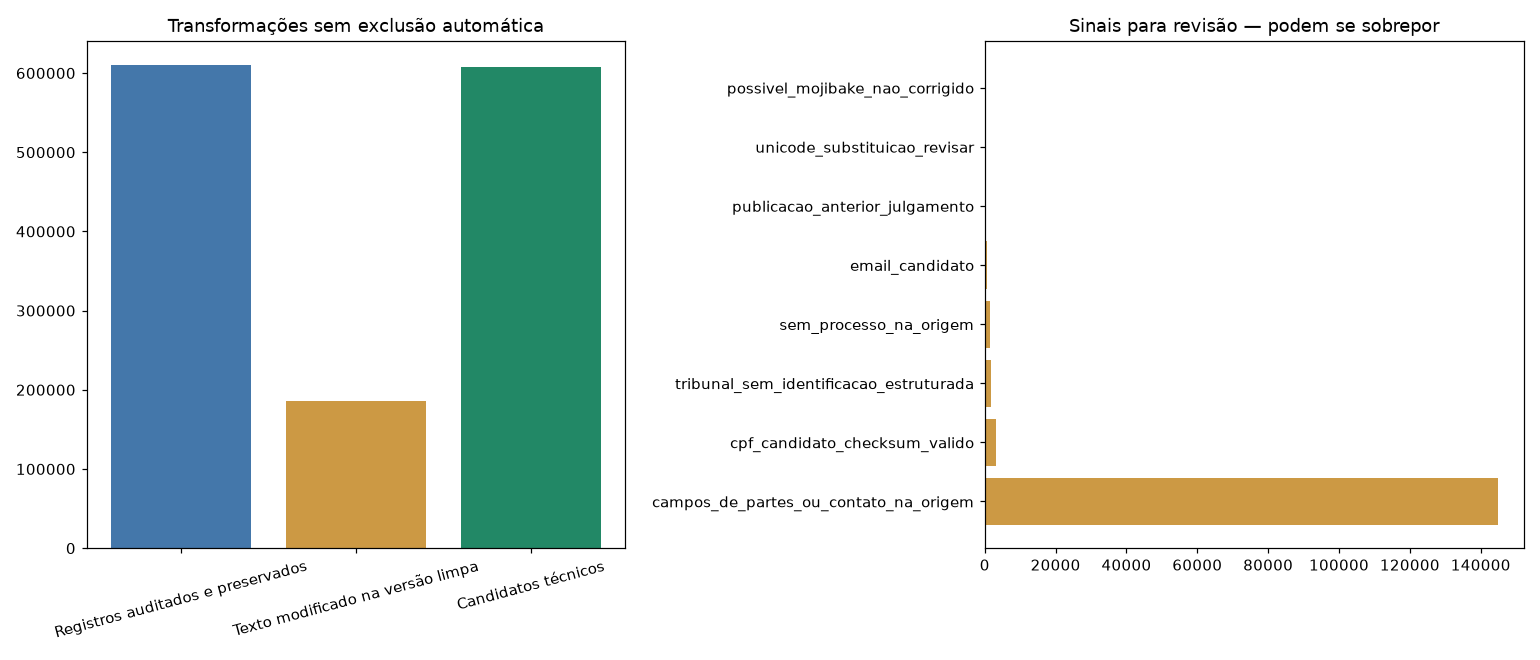

In [20]:
figuras_estrutura=structure.figures(STRUCT_REPORT,resumo_estrutura)
plt.show()

## 10. Verificação automática da base tratada, cópias e partições

As verificações abaixo foram executadas sobre o corpus pós-PLN. O relatório distingue evidência declarada, inferências por regras e alertas computacionais. Os resultados são registrados por métodos automáticos; seu alcance não comprova aprovação jurídica ou anonimização integral.

In [21]:
from src.jurisprudencia import automatic_review
AUTO_DIR,resumo_auto=automatic_review.load(ROOT_JUR)
assert resumo_auto['registros']==609872
assert audit.hash_file(ROOT_JUR/resumo_auto['indice'])==resumo_auto['indice_sha256']
display(pd.Series({k:resumo_auto[k] for k in ['registros','textos_vazios','candidatos_rag_criterios_automaticos','candidatos_consolidados','grupos_copias_textuais_candidatas','ocorrencias_copias_textuais_excedentes','exclusoes_fisicas']},name='verificacao_automatica').to_frame())
display(pd.read_csv(AUTO_DIR/'alertas_automaticos.csv'))
verificacao_pos_pln=json.loads((AUTO_DIR/'verificacao_independente_pos_pln.json').read_text(encoding='utf-8'))
assert verificacao_pos_pln['vinculos_texto_processo_atravessando_splits']==0
display(pd.Series(verificacao_pos_pln,name='particoes_pos_pln').to_frame())
print('Critérios de uso/recorte:',AUTO_DIR/'criterios_uso_recorte.json')
print('Índice de candidatos e relações:',ROOT_JUR/resumo_auto['indice'])
print(resumo_auto['limites'])


Critérios de uso/recorte: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\jurisprudencia\automacao\4dfbcfe6b1cf461dbea9698d1b6f8b5843ef985702621493467483ce57b49bce\criterios_uso_recorte.json
Índice de candidatos e relações: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\processed\jurisprudencia\automacao\4dfbcfe6b1cf461dbea9698d1b6f8b5843ef985702621493467483ce57b49bce\indice_automatico.parquet
Critérios automáticos versionados, sem parecer jurídico. Triagem temática e inferência de conteúdo examinam até 8.000 caracteres. Cópia textual candidata não comprova identidade de acórdão. Vínculos semânticos não reconhecidos podem não ser agrupados.


,verificacao_automatica
registros,609872
textos_vazios,0
candidatos_rag_criterios_automaticos,456784
candidatos_consolidados,456750
grupos_copias_textuais_candidatas,63
ocorrencias_copias_textuais_excedentes,65
exclusoes_fisicas,0


,alerta,registros
0,inteiro_teor_curto,14329
1,origem_sem_correspondencia_hash,10000
2,possivel_mojibake_nao_corrigido,13
3,publicacao_anterior_julgamento,106
4,sem_datas,1
5,texto_menor_80,10041
6,tribunal_nao_identificado,1689
7,unicode_substituicao_revisar,56


,particoes_pos_pln
registros_verificados,609872
vinculos_texto_processo_atravessando_splits,0
indice_sha256,1900b357cfe05ac193547df4e34aaded8d81bb6f4150bf...
metodo,Conferência independente de cada chave de text...
limite,Não cobre vínculos semânticos ou identidade pr...


## 11. Conclusão e próximos passos atualizados

A estruturação e o mascaramento de CPFs estão concluídos para os 609.872 registros dos 19 arquivos ativos. Os originais permanecem separados da derivada protegida. A origem de 18 arquivos ativos foi confirmada; a origem individual do JSON TST continua pendente. O arquivo ilegível está somente no histórico, e a cópia adicional de 50.000 registros STF permanece separada.

As verificações automáticas de conteúdo, privacidade, relações e partições estão no seção de verificação automática. O JSON TST continua sem correspondência de origem e recebe um alerta computacional. A seleção de candidatos usa critérios documentados; os textos protegidos e seus próprios offsets são a referência para uma integração futura. Não houve treinamento ou alteração do RAG legislativo.

In [22]:
from src.jurisprudencia import presentation
conclusao_estrutura_atual = presentation.conclusion(ROOT_JUR, 'estrutura', dataset.conclusion(ROOT_JUR))
(STRUCT_REPORT/'conclusao_estrutura_atualizada.md').write_text(conclusao_estrutura_atual,encoding='utf-8')
display(Markdown(conclusao_estrutura_atual))


# Conclusão da limpeza e estruturação

Foram preservados **609,872 registros** em **19 shards canônicos**, com **0 exclusões automáticas**. A reconciliação com a auditoria é **True**. O arquivo ilegível permanece somente no histórico, fora dos 19 arquivos ativos.

## Texto e metadados

Em 186,311 registros, a versão limpa difere da versão textual original selecionada. As duas são preservadas, com hashes e operações. As regras tratam HTML, NFC Unicode, BOM, espaços, quebras de linha e controles de apresentação. Não há remoção de stopwords ou reescrita jurídica. HTML não balanceado, RTF e possíveis problemas de codificação ficam identificados para conferência.

Julgamento, publicação e assinatura têm campos separados. A data de referência temporal pode ser assinatura quando assim identificada; não é promovida a julgamento. O processo original é preservado, e a extração de CNJ é sintática, sem validação de dígitos verificadores. As informações não mapeadas permanecem recuperáveis nas fontes pela linhagem de arquivo/hash/linha e pelo hash do registro original.

Há 608,183 candidatos pelos critérios técnicos mínimos. Esse indicador não aprova privacidade, licença, pertinência temática ou correção jurídica. A base inteira continua marcada como **não anonimizada e sujeita a revisão**.

## Repetições

O índice lateral registra repetições de texto limpo, processo e chave documental candidata. Nenhum desses grupos remove dados. Mesmo processo pode ter várias decisões e os identificadores dos produtores podem ter namespaces distintos. Os critérios podem se sobrepor.

Use `src.jurisprudencia.dataset.open_dataset(root)` para abrir somente os shards canônicos. O arquivo `sinais_repeticao.parquet` é um índice lateral, não outro conjunto de decisões. Ler todos os Parquet indiscriminadamente pode duplicar a contagem de linhas.

O índice `grupos_processuais.parquet` usa CNJ sintático sem prefixo do tribunal julgador para reunir referências ao mesmo processo entre graus de jurisdição. Números antigos mantêm namespace de tribunal; exigem revisão quando houver formas diferentes. Esse agrupamento não valida dígitos verificadores nem cria uma partição de avaliação automaticamente.

## Escopo e versões dos dados

O escopo ativo contém **19 arquivos e 609.872 registros**, em acordo com os notebooks 01 e 02. O arquivo ilegível foi excluído do escopo ativo; seu registro permanece somente no histórico. A origem de **18 dos 19 arquivos ativos** está confirmada por hash e tamanho; a origem individual do JSON TST continua pendente. A cópia oficial adicional de **50.000 registros STF permanece separada**.

**Base canônica original:** preserva os textos original e limpo, a linhagem e os sinais de revisão; pode conter dados pessoais. As tabelas de normalização e os sinais da auditoria referem-se a essa versão.

**Derivada protegida:** o CSV e os shards Parquet contêm texto/ementa com sequências compatíveis com CPF substituídas por `[CPF_REMOVIDO]`. Foram alterados **5.695 registros**, com **13.294 substituições**. A releitura integral validou os **609.872 registros** do CSV, sem resíduos dos padrões tratados nos campos de conteúdo. Os textos originais não foram exportados nessa derivada.

O mascaramento de CPF está concluído. A verificação automática posterior registra alertas de privacidade, inferência de conteúdo e sinais temáticos; outros dados pessoais não são considerados integralmente anonimizados. Os grupos e as partições foram recalculados após o PLN e conferidos para os vínculos conhecidos. Não houve publicação, indexação ou treinamento.

Referências: [Revisão](#verificacao-automatica), [Origens](#fontes-proveniencia) e [regras de proteção](../../docs/protecao_cpf_jurisprudencia.md).

**PLN leve concluído:** formatação/entidades HTML, NFC e separação de `ementa` e `inteiro_teor` foram auditados. O CSV final foi relido integralmente, e o mascaramento foi reaplicado aos textos decodificados. Candidatos a ruído e comparações antes/depois possuem verificações por regras; os trechos incertos permanecem preservados com alertas. Use `data/processed/jurisprudencia/pln_leve/ativa.json` para localizar a versão tratada.
